# 04 - Evaluate: choose, set the threshold, look at July once

1. The two models from notebook 03, refitted on May, compared on June, and one chosen
2. **The threshold, from costs we argue** (and how much it moves if the costs are different)
3. A reliability check: does a score of 0.3 mean a 30% chance of crawling?
4. Results by slice on June: where the model works and where it does not
5. **Which crawls the warning misses**
6. **July, scored once**, with bootstrap intervals
7. Summary for the model card

Every choice in sections 1 to 5 is made on June. July is scored in one cell, after everything is fixed, and nothing is changed afterwards.

In [1]:
import sys; sys.path.insert(0, "..")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import average_precision_score, brier_score_loss
from src.clean import *
from src.features import *
from src.models import *
from src.evaluate import *
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
REPORTS = Path("../reports")
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2})

df, _ = build_dataset()
train = df[df.split == "train"].reset_index(drop=True)
val = df[df.split == "validation"].reset_index(drop=True)
test = df[df.split == "test"].reset_index(drop=True)      # not touched until section 6
del df
ytr, yva = train.crawl.to_numpy(), val.crawl.to_numpy()

choice = json.loads((REPORTS / "selected_features.json").read_text())
FEATS = choice["features"]
print("features chosen in notebook 03:", FEATS)
print("tree:", choice["tree"], " logistic regression:", choice["logreg"])

features chosen in notebook 03: ['hour', 'weekday', 'is_rush', 'pu_rate', 'do_rate', 'pair_rate', 'pu_slot_rate']
tree: {'max_depth': 16, 'min_samples_leaf': 200}  logistic regression: {'C': 1.0}


## 1. Choose the model on June
Both models are the leak-free pipelines from notebook 03 (`make_pipeline`), fitted on May only. **Rule:** take the higher June PR AUC; if the two are within 0.005, take the logistic regression, because its probabilities are smoother (every trip gets its own score instead of sharing a leaf), it is easier to explain, and it is usually better calibrated.

In [2]:
models = {
    "logistic regression": make_pipeline(make_logreg(choice["logreg"]["C"]), FEATS, scale=True),
    "decision tree": make_pipeline(make_tree(choice["tree"]["max_depth"], min_samples_leaf=choice["tree"]["min_samples_leaf"]),
                                   FEATS, scale=False),
}
p_val = {}
for name, m in models.items():
    m.fit(train, ytr)
    p_val[name] = m.predict_proba(val)[:, 1]

ap = {k: average_precision_score(yva, p) for k, p in p_val.items()}
best = max(ap, key=ap.get)
if abs(ap["logistic regression"] - ap["decision tree"]) < 0.005:
    best = "logistic regression"
CHOSEN = best; final = models[CHOSEN]; pv = p_val[CHOSEN]
print({k: round(v, 4) for k, v in ap.items()}, "->", CHOSEN)

{'logistic regression': 0.627, 'decision tree': 0.6277} -> logistic regression


## 2. The threshold, from costs
**What a mistake costs.** The warning is a message the dispatcher sends before the trip starts ("heavy traffic expected, your ride may take much longer than usual").

* **A missed crawl (false negative), cost 3.** The passenger was not warned and sits in traffic at walking pace. They miss a train or a meeting, blame the service, and may not book again. They also lose the chance to act on the warning: leave earlier, take the subway, or change the drop-off. This is the harm the product exists to prevent.
* **A needless warning (false positive), cost 1.** The passenger gets a warning and the trip is fine. The cost is small but real: some cancel and take the subway (a lost fare), and if warnings are often wrong, people stop reading them. That last effect is why a needless warning is not free.

We set the ratio at **3 to 1**: one missed crawl hurts as much as three needless warnings. With these costs the best threshold, if the scores were perfectly calibrated, would be 1 / (1 + 3) = 0.25. We do not take 0.25 on trust: we pick the threshold with the lowest expected cost on June, and then show how it moves if the ratio is 2 or 5 instead.

In [3]:
curve = cost_curve(yva, pv)
THR = best_threshold(yva, pv)
at = curve.set_index("threshold").loc[THR]
never = expected_cost(yva, np.zeros_like(pv), 0.5)
always = expected_cost(yva, np.ones_like(pv), 0.5)
print(f"chosen threshold {THR:.2f}: cost {at.cost_per_1000:.0f} per 1,000 trips (never warn {never:.0f}, warn everyone {always:.0f}); "
      f"precision {at.precision:.3f}, recall {at.recall:.3f}, warns {at['warned_%']:.1f}% of trips")

sens = []
for ratio in [1, 2, 3, 5, 10]:
    t = best_threshold(yva, pv, cost_fn=ratio, cost_fp=1)
    c = cost_curve(yva, pv, [t], cost_fn=ratio, cost_fp=1).iloc[0]
    sens.append({"missed crawl : needless warning": f"{ratio} : 1", "best threshold": t, "precision": c.precision,
                 "recall": c.recall, "warned_%": c["warned_%"]})
sens = pd.DataFrame(sens).set_index("missed crawl : needless warning")
sens.round(3)

chosen threshold 0.26: cost 287 per 1,000 trips (never warn 556, warn everyone 815); precision 0.506, recall 0.717, warns 26.3% of trips


,best threshold,precision,recall,warned_%
missed crawl : needless warning,,,,
1 : 1,0.52,0.687,0.425,11.458
2 : 1,0.34,0.569,0.622,20.231
3 : 1,0.26,0.506,0.717,26.287
5 : 1,0.18,0.430,0.818,35.249
10 : 1,0.11,0.345,0.906,48.630


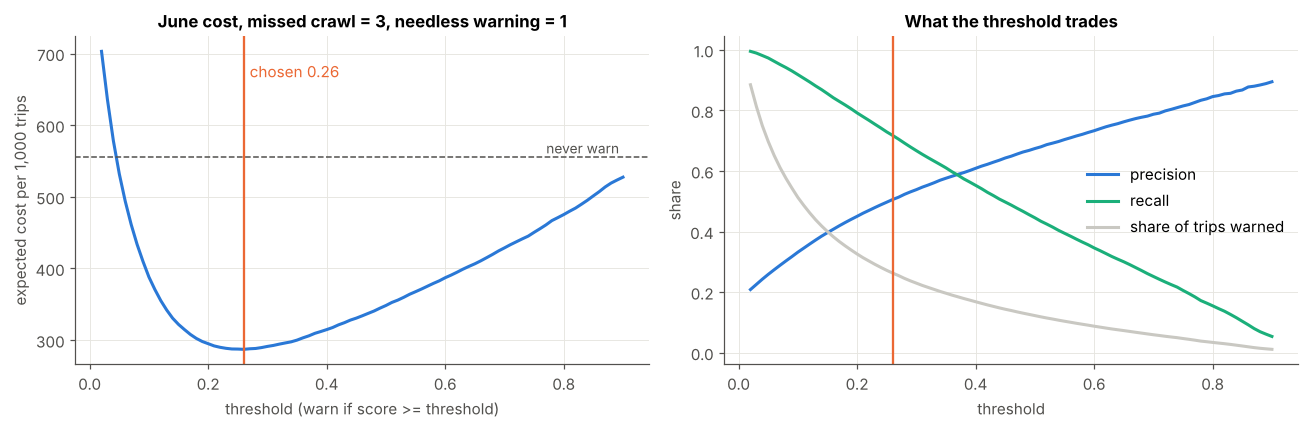

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(curve.threshold, curve.cost_per_1000, color=BLUE)
ax[0].axhline(never, color=INK, lw=1, ls="--"); ax[0].text(0.9, never, "never warn ", ha="right", va="bottom", color=INK, fontsize=9)
ax[0].axvline(THR, color=ORANGE, lw=1.5); ax[0].text(THR + 0.01, ax[0].get_ylim()[1] * 0.95, f"chosen {THR:.2f}", color=ORANGE, va="top")
ax[0].set(xlabel="threshold (warn if score >= threshold)", ylabel="expected cost per 1,000 trips")
ax[0].set_title("June cost, missed crawl = 3, needless warning = 1")
ax[1].plot(curve.threshold, curve.precision, color=BLUE, label="precision")
ax[1].plot(curve.threshold, curve.recall, color=AQUA, label="recall")
ax[1].plot(curve.threshold, curve["warned_%"] / 100, color=GREY, label="share of trips warned")
ax[1].axvline(THR, color=ORANGE, lw=1.5)
ax[1].set(xlabel="threshold", ylabel="share"); ax[1].set_title("What the threshold trades"); ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "04_cost_threshold.png", bbox_inches="tight"); plt.show()

**Reading it.** The sensitivity table shows how much the decision depends on the 3 : 1 assumption. If a team or a dispatcher disagrees with our costs, they can read off the threshold for their own ratio instead of re-running anything.

## 3. Reliability check (June)
If the scores are calibrated, trips scored around 0.3 should crawl about 30% of the time. The trips are cut into 10 equal-size groups by score; each point compares the average score of a group with the share that actually crawled.

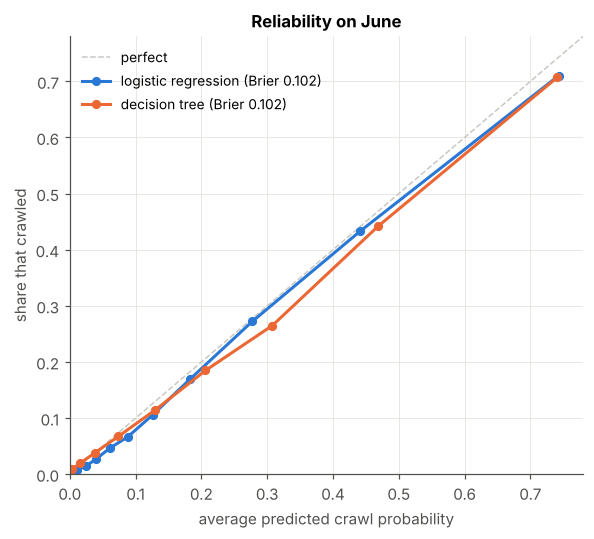

,predicted,observed,trips
bin,,,
0,0.010,0.007,18619
1,0.025,0.015,18618
2,0.040,0.027,18618
3,0.061,0.046,18619
4,0.088,0.067,18618
5,0.126,0.106,18618
6,0.183,0.170,18619
7,0.277,0.272,18618
8,0.442,0.433,18618


In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls="--", label="perfect")
rel = {}
for (name, p), col in zip(p_val.items(), [BLUE, ORANGE]):
    r = reliability_table(yva, p); rel[name] = r
    ax.plot(r.predicted, r.observed, color=col, marker="o", ms=5, label=f"{name} (Brier {brier_score_loss(yva, p):.3f})")
lim = max(max(r.predicted.max(), r.observed.max()) for r in rel.values()) * 1.05
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="average predicted crawl probability", ylabel="share that crawled")
ax.set_title("Reliability on June"); ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "04_reliability.png", bbox_inches="tight"); plt.show()
rel[CHOSEN].round(3)

**Reading it.** Points below the diagonal mean the model over-states the risk. Part of any gap is expected: the crawl rate is 19.3% in May (the training month) and 18.5% in June, so a model trained on May is slightly too pessimistic on June. That is one more reason the threshold is chosen on June rather than set to 0.25, and why it should be re-checked every month.

## 4. Results by slice (June)
Same model, same threshold, split by kinds of trip. PR AUC is shown only where a slice has both crawls and non-crawls.

In [6]:
def add_slices(d):
    t = d.tpep_pickup_datetime; h, wd = t.dt.hour, t.dt.dayofweek
    out = pd.DataFrame(index=d.index)
    out["time"] = np.select([wd >= 5, h < 6, h < 16, h < 20], ["weekend", "weekday night 0-5h", "weekday day 6-15h", "weekday rush 16-19h"],
                            "weekday evening 20-23h")
    out["pickup borough"] = d.pickup_borough
    pm, dm = d.pickup_borough == "Manhattan", d.dropoff_borough == "Manhattan"
    out["route"] = np.select([pm & dm, pm ^ dm], ["within Manhattan", "Manhattan <-> other"], "outside Manhattan")
    out["airport"] = np.where(d.PULocationID.isin(AIRPORT_ZONES) | d.DOLocationID.isin(AIRPORT_ZONES), "airport trip", "no airport")
    out["payment"] = np.where(d.is_flex == 1, "flex fare", "metered")
    out["booked by app (request_source)"] = np.where(d.request_source.notna(), "filled", "empty") if "request_source" in d else "empty"
    out["measured distance"] = pd.cut(d.trip_distance, [0, 1, 2, 5, np.inf], labels=["< 1 mi", "1-2 mi", "2-5 mi", "5+ mi"], right=False).astype(str)
    return out

def slice_table(d, y, p, thr):
    s = add_slices(d); rows = []
    for col in s.columns:
        for val_, idx in s.groupby(col).groups.items():
            yy, pp = y[idx], p[idx]
            if len(yy) < 200: continue
            warn = pp >= thr; tp = (warn & (yy == 1)).sum()
            rows.append({"slice": col, "group": val_, "trips": len(yy), "crawl_rate": yy.mean(),
                         "pr_auc": average_precision_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan,
                         "precision": tp / max(warn.sum(), 1), "recall": tp / max(yy.sum(), 1),
                         "warned_%": 100 * warn.mean(), "share_of_all_crawls_%": 100 * yy.sum() / y.sum()})
    return pd.DataFrame(rows).set_index(["slice", "group"])

sl_val = slice_table(val, yva, pv, THR)
sl_val.round(3)

trips  crawl_rate  pr_auc  precision  recall  warned_%  share_of_all_crawls_%
slice                          group                                                                                                 
time                           weekday day 6-15h        62898       0.273   0.692      0.522   0.828    43.385                 49.829
                               weekday evening 20-23h   31835       0.086   0.385      0.412   0.424     8.896                  7.969
                               weekday night 0-5h        9155       0.018   0.112      0.123   0.048     0.710                  0.484
                               weekday rush 16-19h      31668       0.258   0.660      0.519   0.746    37.069                 23.683
                               weekend                  50628       0.123   0.479      0.463   0.522    13.862                 18.035
pickup borough                 Bronx                      666       0.035   0.116      0.111   0.043     1.351                  0.067
                               Brooklyn                  5138       0.037   0.100      0.161   0.048     1.090                  0.545
                               Manhattan               165309       0.207   0.631      0.506   0.723    29.563                 99.108
                               Queens                   15057       0.006   0.070      0.286   0.021     0.046                  0.281
route                          Manhattan <-> other      21904       0.009   0.030      0.047   0.149     2.817                  0.565
                               outside Manhattan         9699       0.023   0.087      0.184   0.032     0.392                  0.635
                               within Manhattan        154581       0.221   0.636      0.512   0.725    31.237                 98.800
airport                        airport trip             15020       0.003   0.007      0.027   0.053     0.499                  0.110
                               no airport              171164       0.201   0.629      0.507   0.718    28.550                 99.890
payment                        flex fare                46955       0.102   0.489      0.454   0.529    11.907                 13.886
                               metered                 139229       0.213   0.646      0.513   0.748    31.136                 86.114
booked by app (request_source) empty                   139245       0.213   0.646      0.513   0.748    31.134                 86.117
                               filled                   46939       0.102   0.489      0.454   0.530    11.909                 13.883
measured distance              1-2 mi                   58173       0.246   0.631      0.501   0.738    36.197                 41.391
                               2-5 mi                   56135       0.097   0.378      0.370   0.520    13.601                 15.740
                               5+ mi                    33956       0.003   0.019      0.021   0.194     2.568                  0.269
                               < 1 mi                   37920       0.388   0.715      0.586   0.773    51.102                 42.599

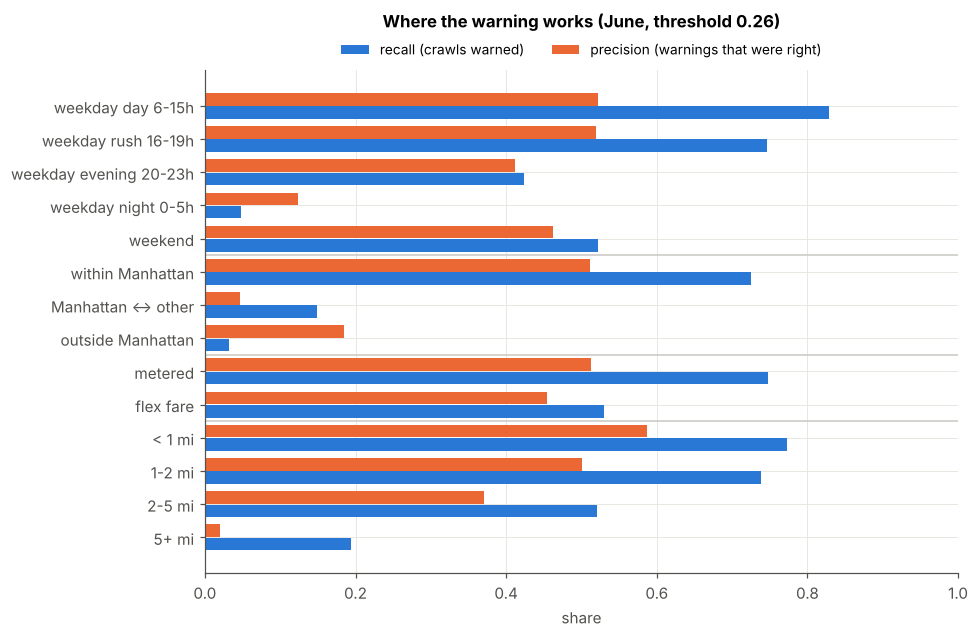

In [7]:
ORDER = {"time": ["weekday day 6-15h", "weekday rush 16-19h", "weekday evening 20-23h", "weekday night 0-5h", "weekend"],
         "route": ["within Manhattan", "Manhattan <-> other", "outside Manhattan"], "payment": ["metered", "flex fare"],
         "measured distance": ["< 1 mi", "1-2 mi", "2-5 mi", "5+ mi"]}
show = sl_val.loc[[(k, g) for k, gs in ORDER.items() for g in gs if (k, g) in sl_val.index]]
labels = [f"{g}" for _, g in show.index]
fig, ax = plt.subplots(figsize=(9, 0.35 * len(show) + 1))
y_ = np.arange(len(show))
ax.barh(y_ + 0.2, show.recall, 0.38, color=BLUE, label="recall (crawls warned)")
ax.barh(y_ - 0.2, show.precision, 0.38, color=ORANGE, label="precision (warnings that were right)")
ax.set_yticks(y_, labels); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("share")
group_starts = [i for i, (s, _) in enumerate(show.index) if i == 0 or show.index[i - 1][0] != s]
for i in group_starts[1:]: ax.axhline(i - 0.5, color=GREY, lw=1)
ax.set_title(f"Where the warning works (June, threshold {THR:.2f})", pad=28)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "04_slices.png", bbox_inches="tight"); plt.show()

## 5. Which crawls does the warning miss?
The model card must say this plainly. Below: of all June crawls that got **no** warning, what kind of trips they were, compared with the crawls that were caught.

In [8]:
s = add_slices(val)
crawl = yva == 1; caught = crawl & (pv >= THR); missed = crawl & (pv < THR)
print(f"June: {crawl.sum():,} crawls; warned {caught.sum():,} ({100 * caught.sum() / crawl.sum():.1f}%), missed {missed.sum():,} ({100 * missed.sum() / crawl.sum():.1f}%)")
miss_tab = {}
for col in ["time", "route", "payment", "measured distance", "pickup borough"]:
    t = pd.DataFrame({"missed crawls %": s[missed][col].value_counts(normalize=True) * 100,
                      "caught crawls %": s[caught][col].value_counts(normalize=True) * 100,
                      "miss rate within group %": (s[crawl].assign(m=missed[crawl]).groupby(col).m.mean() * 100)}).fillna(0)
    miss_tab[col] = t.sort_values("missed crawls %", ascending=False).round(1)
    display(miss_tab[col])

June: 34,510 crawls; warned 24,755 (71.7%), missed 9,755 (28.3%)


,missed crawls %,caught crawls %,miss rate within group %
time,,,
weekend,30.5,13.1,47.8
weekday day 6-15h,30.3,57.5,17.2
weekday rush 16-19h,21.3,24.6,25.4
weekday evening 20-23h,16.2,4.7,57.6
weekday night 0-5h,1.6,0.0,95.2


,missed crawls %,caught crawls %,miss rate within group %
route,,,
within Manhattan,96.1,99.9,27.5
outside Manhattan,2.2,0.0,96.8
Manhattan <-> other,1.7,0.1,85.1


,missed crawls %,caught crawls %,miss rate within group %
payment,,,
metered,76.9,89.8,25.2
flex fare,23.1,10.2,47.1


,missed crawls %,caught crawls %,miss rate within group %
measured distance,,,
1-2 mi,38.3,42.6,26.2
< 1 mi,34.2,45.9,22.7
2-5 mi,26.7,11.4,48.0
5+ mi,0.8,0.1,80.6


,missed crawls %,caught crawls %,miss rate within group %
pickup borough,,,
Manhattan,97.0,100.0,27.7
Brooklyn,1.8,0.0,95.2
Queens,1.0,0.0,97.9
Bronx,0.2,0.0,95.7


In [9]:
# the zones that produce the most unwarned crawls
mz = (val[missed].groupby("pickup_zone").size().rename("missed crawls").to_frame()
      .join(val[crawl].groupby("pickup_zone").size().rename("all crawls")))
mz["miss rate %"] = (100 * mz["missed crawls"] / mz["all crawls"]).round(1)
mz.sort_values("missed crawls", ascending=False).head(10)

,missed crawls,all crawls,miss rate %
pickup_zone,,,
Upper East Side North,441,1273,34.6
East Village,415,616,67.4
Upper East Side South,378,2389,15.8
West Village,333,704,47.3
Lincoln Square East,331,799,41.4
Midtown Center,328,2928,11.2
Upper West Side South,314,409,76.8
East Chelsea,297,1189,25.0
Penn Station/Madison Sq West,286,1882,15.2


**Reading it.** A warning built from the time and the zones can only catch crawls that are *typical* for that time and route. It cannot see a one-off accident, a parade, a closed bridge or the weather, so crawls on routes that are usually fast are the ones it misses. The tables show which groups these are; the model card repeats them.

## 6. July, scored once
Everything is fixed: the features (notebook 03), the model and the threshold (sections 1 and 2). The model is the one fitted on May. July is scored in this one cell, with 1,000 bootstrap resamples of July trips for the intervals, next to the baselines and the 'never warn' cost on July. Nothing above is changed after this cell has run.

In [10]:
yte = test.crawl.to_numpy()
pt = final.predict_proba(test)[:, 1]
boot = bootstrap(yte, pt, THR, n=1000, seed=0)

rule = BusyRule().fit(train)
M, _ = build_matrix(train, {"test": test})
tree2 = make_tree(2).fit(M["train"][ALL_FEATS], ytr)
july_ladder = metrics_table({
    "1 always 'no crawl'": (AlwaysNo().predict_proba(test)[:, 1], THR),
    "2 busy-hours rule": (rule.predict_proba(test)[:, 1], THR),
    "3 depth-2 tree": (tree2.predict_proba(M["test"][ALL_FEATS])[:, 1], THR),
    f"{CHOSEN} (chosen)": (pt, THR),
}, yte)
sl_test = slice_table(test, yte, pt, THR)
never_july = expected_cost(yte, np.zeros_like(pt), 0.5)

print(f"JULY, scored once: {CHOSEN}, threshold {THR:.2f}, {len(yte):,} trips, crawl rate {yte.mean():.3f}")
display(boot.round(3))
display(july_ladder.round(3))
print(f"cost if never warning in July: {never_july:.0f} per 1,000 trips")

JULY, scored once: logistic regression, threshold 0.26, 185,560 trips, crawl rate 0.163


,value,low_95,high_95
pr_auc,0.610,0.604,0.616
pr_auc_lift,3.740,3.701,3.780
precision,0.455,0.450,0.459
recall,0.767,0.762,0.772
cost_per_1000,264.367,261.198,267.170
lift@10%,4.156,4.113,4.197


,pr_auc,precision,recall,lift@10%,pr_auc_lift,warned_%,base_rate,cost_per_1000
1 always 'no crawl',0.163,0.000,0.000,0.826,1.000,0.000,0.163,489.545
2 busy-hours rule,0.217,0.273,0.489,1.509,1.329,29.243,0.163,462.659
3 depth-2 tree,0.432,0.432,0.656,3.535,2.645,24.798,0.163,309.091
logistic regression (chosen),0.610,0.455,0.767,4.156,3.740,27.523,0.163,264.367


cost if never warning in July: 490 per 1,000 trips


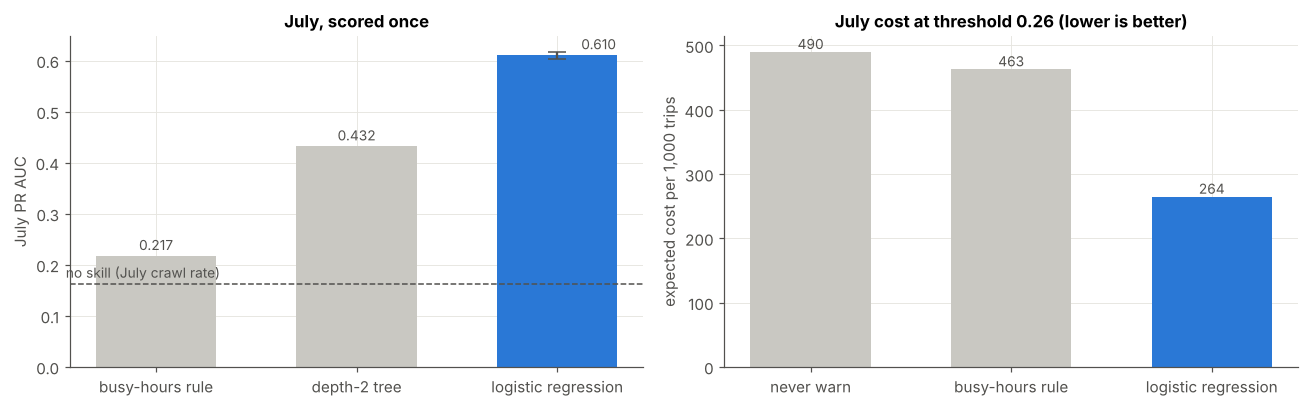

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
names = ["busy-hours rule", "depth-2 tree", CHOSEN]
vals = july_ladder["pr_auc"].iloc[1:].to_numpy()
ax[0].bar(names, vals, color=[GREY, GREY, BLUE], width=0.6)
ax[0].errorbar(2, boot.loc["pr_auc", "value"], yerr=[[boot.loc["pr_auc", "value"] - boot.loc["pr_auc", "low_95"]],
               [boot.loc["pr_auc", "high_95"] - boot.loc["pr_auc", "value"]]], color=INK, capsize=6, lw=1.5)
ax[0].axhline(yte.mean(), color=INK, lw=1, ls="--"); ax[0].text(-0.45, yte.mean() + 0.005, "no skill (July crawl rate)", va="bottom", ha="left", color=INK, fontsize=9)
for i, v in enumerate(vals): ax[0].text(i + 0.12 * (i == 2), v + 0.012, f"{v:.3f}", ha="left" if i == 2 else "center", color=INK, fontsize=9)
ax[0].set_ylabel("July PR AUC"); ax[0].set_title("July, scored once")
costs = [never_july, july_ladder.loc["2 busy-hours rule", "cost_per_1000"], july_ladder.loc[f"{CHOSEN} (chosen)", "cost_per_1000"]]
ax[1].bar(["never warn", "busy-hours rule", CHOSEN], costs, color=[GREY, GREY, BLUE], width=0.6)
for i, v in enumerate(costs): ax[1].text(i, v + 5, f"{v:.0f}", ha="center", color=INK, fontsize=9)
ax[1].set_ylabel("expected cost per 1,000 trips"); ax[1].set_title(f"July cost at threshold {THR:.2f} (lower is better)")
fig.tight_layout(); fig.savefig(FIG / "04_july.png", bbox_inches="tight"); plt.show()

In [12]:
sl_test.loc[["time", "route", "payment", "booked by app (request_source)"]].round(3)

trips  crawl_rate  pr_auc  precision  recall  warned_%  share_of_all_crawls_%
slice                          group                                                                                                 
time                           weekday day 6-15h        64296       0.239   0.660      0.457   0.858    45.006                 50.845
                               weekday evening 20-23h   31858       0.082   0.377      0.395   0.466     9.646                  8.593
                               weekday night 0-5h        9121       0.012   0.098      0.190   0.108     0.691                  0.367
                               weekday rush 16-19h      32151       0.237   0.671      0.494   0.802    38.453                 25.162
                               weekend                  48134       0.095   0.457      0.402   0.585    13.787                 15.033
route                          Manhattan <-> other      23739       0.009   0.026      0.039   0.135     3.138                  0.710
                               outside Manhattan        10423       0.020   0.077      0.175   0.034     0.384                  0.687
                               within Manhattan        151398       0.197   0.619      0.461   0.776    33.215                 98.603
payment                        flex fare                48449       0.084   0.482      0.403   0.584    12.194                 13.478
                               metered                 137111       0.191   0.628      0.461   0.795    32.940                 86.522
booked by app (request_source) empty                   137122       0.191   0.628      0.461   0.795    32.938                 86.526
                               filled                   48438       0.084   0.482      0.403   0.584    12.195                 13.474

In [13]:
results = {
    "model": CHOSEN, "features": FEATS, "threshold": THR, "costs": {"missed_crawl": COST_FN, "needless_warning": COST_FP},
    "june": {"pr_auc": float(ap[CHOSEN]), "precision": float(at.precision), "recall": float(at.recall),
             "cost_per_1000": float(at.cost_per_1000), "never_warn_cost": float(never), "positive_rate": float(yva.mean())},
    "july": {k: {"value": float(boot.loc[k, "value"]), "low_95": float(boot.loc[k, "low_95"]), "high_95": float(boot.loc[k, "high_95"])}
             for k in boot.index},
    "july_never_warn_cost": float(never_july), "july_positive_rate": float(yte.mean()),
    "july_baselines_pr_auc": july_ladder["pr_auc"].round(4).to_dict(),
}
(REPORTS / "july_results.json").write_text(json.dumps(results, indent=2))
print("saved reports/july_results.json")

saved reports/july_results.json


## 7. Summary
The numbers for the model card and the README are printed by the cells above and saved in `reports/july_results.json`. The bootstrap intervals show sampling noise **within July** only: they do not cover the drift from one month to the next (the crawl rate falls from May to July and app-booked flex trips appear from June), which is the bigger risk in use. The threshold was chosen on June and should be re-checked on each new month before it is trusted.